# Session 3 复现：从眼区亮度到眨眼信号

对应课程 *Building a Blink Detection Pipeline* 的后半段与 `final_session.ipynb`。

前面已经有了 1841 帧的"眼区裁片"。这一节把它压成**一条一维信号**，然后回答：

1. 这条信号长什么样？有没有缓慢漂移？
2. 漂移能不能扣掉？
3. 扣掉之后，短时的起伏是否和人工标注的眨眼对得上？
4. 如果要用它自动检测眨眼，阈值该放在哪里？

最后一步是课程留给学生的思考题（"uncomment 那行 `axhline`，改变 y 值找阈值"）。
这里不仅要找到阈值，还要说清楚**找阈值的依据是什么**。

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd()
if (PROJECT / "src").exists():
    sys.path.insert(0, str(PROJECT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config

config.setup_matplotlib()

import blink_signal as bs
import pipeline

pd.set_option("display.width", 120)
FPS = 59.93488876831253

## 1. 一个视频 → 一条信号

对每一帧的眼区裁片求平均亮度，得到 1841 个数字。原本 1841 × 640 × 560 ≈ 6.6 亿
个像素，现在只剩 1841 个 —— 这就是"降维"的实际意义。

顺便检查：提取出的信号长度必须与真值长度一致，否则后面所有对齐都是错的。

In [2]:
eye_brightness = bs.extract_mean_brightness(config.TRACKED_VIDEO)
groundtruth = bs.load_groundtruth()
print(f"Brightness values extracted: {len(eye_brightness)}")
print(f"Ground-truth values available: {len(groundtruth)}")

Brightness values extracted: 1841
Ground-truth values available: 1841


## 2. 真值长什么样

人工标注的是"从眼睛开始闭合的那一帧，到重新睁开的那一帧"，所以真值是 0/1 的阶跃信号，
**没有渐变**。这一点很重要：真值记录的是**事件的边界**，不是"闭合程度"。

,event,start,end,length_frames
0,1,218,244,26
1,2,319,340,21
2,3,647,672,25
3,4,685,723,38
4,5,828,856,28
5,6,893,921,28
6,7,928,961,33
7,8,1082,1116,34
8,9,1124,1160,36
9,10,1498,1552,54


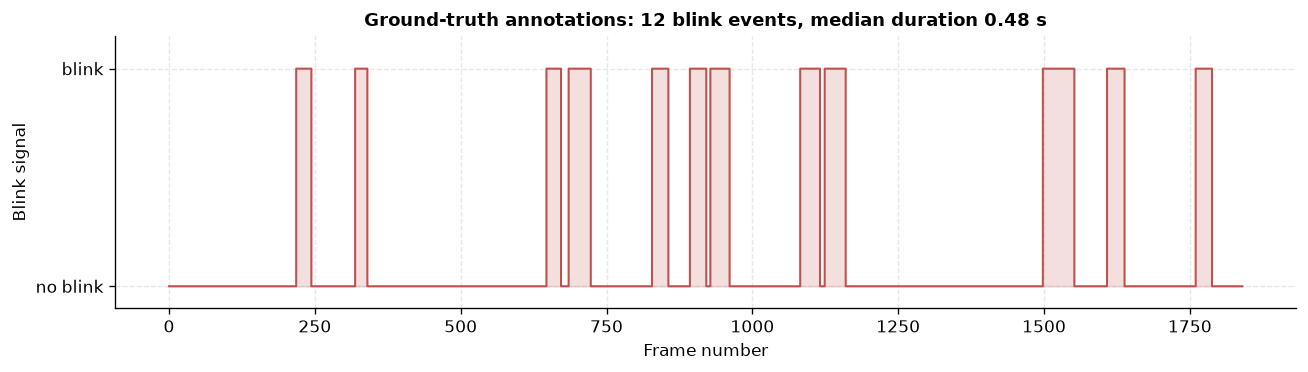

In [3]:
fig_gt, gt_events = bs.plot_groundtruth(groundtruth, FPS)
gt_events

12 次眨眼，占 381 / 1841 = 20.7% 的帧，中位持续 29 帧（≈0.48 s）。
这个比例后面的评估要用：即使什么都不预测，只要阈值很低，召回率天然就高。

## 3. 信号本身

把亮度画出来，第一眼会看到两件事：

* 有一条缓慢下行的趋势（越到后面越暗）；
* 趋势上叠着一串向上的尖峰。

尖峰就是眨眼（眼睑抬起时皮肤/毛发比虹膜亮）。趋势必须扣掉，否则阈值会随时间失效。

In [4]:
raw = pd.Series(eye_brightness)
baseline, corrected = bs.detrend(raw, FPS, config.EYE_BASELINE_SECONDS)

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(raw.index, raw.values, lw=0.7, color="#7f7f7f", label="Eye brightness")
ax.plot(baseline.index, baseline.values, lw=1.6, color="crimson",
        label="Rolling median baseline (3 s)")
ax.set_xlabel("Frame number")
ax.set_ylabel("Mean brightness")
ax.set_title("Eye brightness drifts by ~10 grey levels across the clip")
ax.legend(fontsize=8.5, loc="upper right")
fig.tight_layout()
config.savefig(fig, "fig30b_eye_brightness_baseline");
plt.close(fig)

## 4. 去趋势

窗口长度是关键参数。课程用 3 秒，并留了一道练习："试试更短/更长的窗口，哪个最能
跟上缓慢趋势又不会跟着尖峰跑？"

直觉上的权衡：

* 窗口 **< 眨眼时长（0.5 s）** → 基线跟着尖峰一起动，把信号扣平；
* 窗口 **远大于事件** → 跟不上真实的漂移，残留趋势。

下面把 0.5–8 秒的窗口都算一遍，用**帧级 AUC**（信号区分"眨眼帧/非眨眼帧"的能力）
来选，而不是用眼睛挑。这正是课程练习想要的答案，只不过用数字给出。

In [5]:
window_rows = []
for seconds in [0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8]:
    _, corrected_w = bs.detrend(raw, FPS, seconds)
    quality = bs.signal_quality(corrected_w.to_numpy(), groundtruth)
    window_rows.append({"window_seconds": seconds, "frame_auc": quality["frame_auc"]})
window_table = pd.DataFrame(window_rows).round(3)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.plot(window_table["window_seconds"], window_table["frame_auc"], "o-", color="#1f4e79")
best_row = window_table.loc[window_table["frame_auc"].idxmax()]
ax.scatter([best_row["window_seconds"]], [best_row["frame_auc"]], s=120,
           facecolor="none", edgecolor="crimson", lw=2, zorder=5)
ax.axhline(0.5, color="black", ls="--", lw=1, label="chance")
ax.set_xlabel("Detrending window (s)")
ax.set_ylabel("Frame-level ROC-AUC")
ax.set_title(f"Best window = {best_row['window_seconds']} s (AUC {best_row['frame_auc']:.3f});"
             " course used 3 s")
ax.legend(fontsize=8)
fig.tight_layout()
config.savefig(fig, "fig34_window_choice");
plt.close(fig)
window_table

,window_seconds,frame_auc
0,0.5,0.626
1,1.0,0.669
2,1.5,0.699
3,2.0,0.687
4,2.5,0.683
5,3.0,0.671
6,4.0,0.673
7,5.0,0.652
8,6.0,0.635
9,8.0,0.637


结果：窗口从 0.5 s 的 0.62 上升到 1.5–2 s 的约 0.69，再往长走又回落。
课程选的 3 s 落在平台区（0.67），只比最优值低约 0.02 —— **不算错，但不是最优**。

这个例子说明调参的正确姿势：先定义"好"的量化标准（这里是 AUC），再在参数上扫。
靠肉眼判断"看起来跟得好不好"很容易把窗口选到 1 s 以下，而那恰恰是最差的一段。

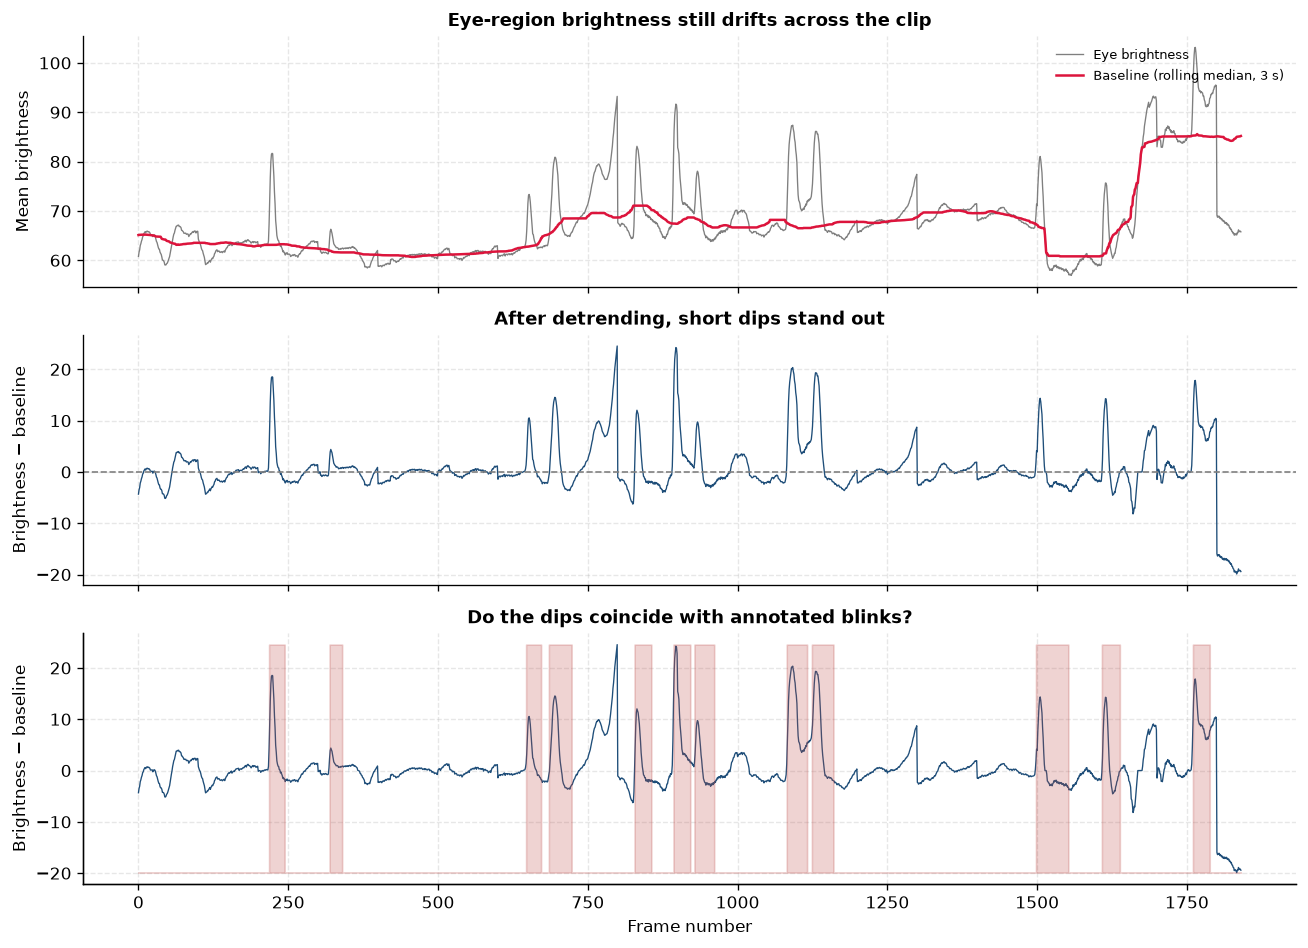

In [6]:
bs.plot_signal_overview(raw, baseline, corrected, FPS);

## 5. 和真值对照

课程用双 y 轴把"亮度信号"和"眨眼真值"叠在一起，然后问：**它们对得上吗？**

对不上的原因课程列了很多（亮度变化滞后于眼睑运动、裁片里混了背景、跟踪漂移、
半眨眼和全眨眼的亮度变化幅度不同……）。这里补一个可量化的版本：

* 帧级 AUC —— 随机取一个眨眼帧和一个非眨眼帧，信号把前者排得更高的概率；
* 点二列相关 —— 信号与 0/1 标签的线性相关。

本例：AUC ≈ **0.67**。这远高于 0.5（有信息），但远低于 0.9（不能当检测器）。

帧级 AUC: 0.671
相关系数: +0.376
极性: 眨眼时更亮


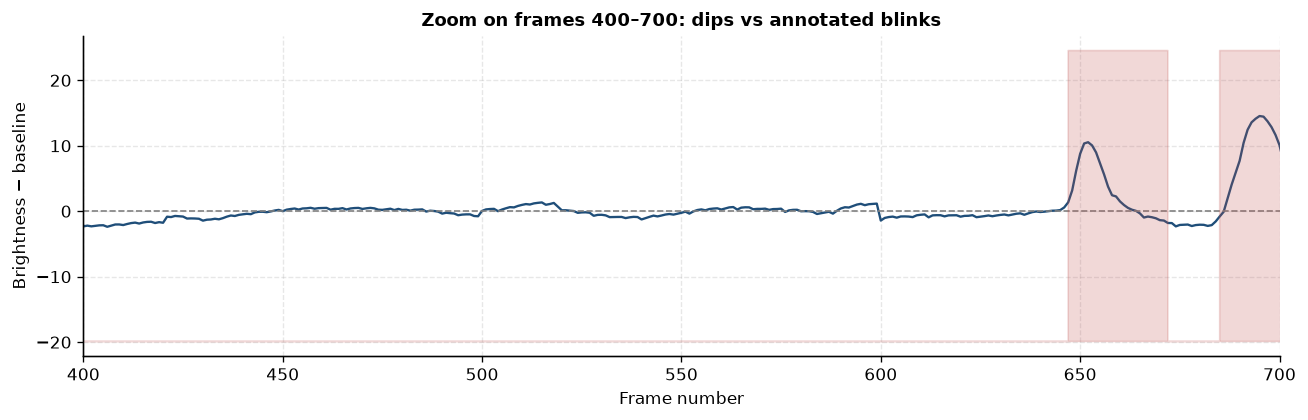

In [7]:
zoom_fig = bs.plot_zoom(corrected, groundtruth, start=400, stop=700)

quality = bs.signal_quality(corrected.to_numpy(), groundtruth)
print(f"帧级 AUC: {quality['frame_auc']:.3f}")
print(f"相关系数: {quality['correlation']:+.3f}")
print(f"极性: {'眨眼时更亮' if quality['polarity'] > 0 else '眨眼时更暗'}")

放大看（400–700 帧）可以发现几个典型现象，这些现象解释了为什么 AUC 只有 0.67：

* 有些尖峰明显对齐标注区间（≈520、600 帧附近）；
* 有些尖峰落在两次眨眼之间 —— 这是马头动了一下，或者反光角度变了；
* 有些标注区间里信号几乎没动 —— 半眨眼，眼睑只盖住一部分瞳孔，平均亮度变化很小。

最后一条最关键：**平均值把"局部变化"平均掉了**。瞳孔被遮 30% 和遮 100%，
平均亮度的差别可能只有几个灰度级，而一次转头可能让平均值动十几个灰度级。

## 6. 阈值该放在哪里

课程让学生手动改 `axhline(y=...)` 找阈值。手动找有两个问题：

1. 只能看局部，容易错过全局最优；
2. 不同人找到的阈值不一样，无法比较。

下面把整条曲线扫一遍，画出精确率 / 召回率 / F1 随阈值的变化。

threshold      0.407
precision      0.582
recall         0.501
f1             0.539
tp           191.000
fp           137.000
fn           190.000
Name: 33, dtype: float64

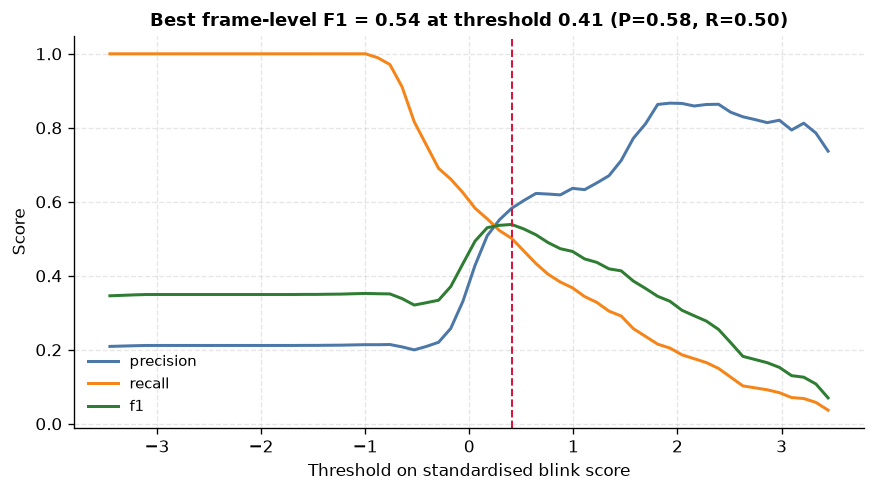

In [8]:
score, polarity = bs.detection_score(corrected.to_numpy(), groundtruth)
sweep = bs.threshold_sweep(score, groundtruth)
best = bs.best_threshold(sweep)
bs.plot_threshold_sweep(sweep, best);
best[["threshold", "precision", "recall", "f1", "tp", "fp", "fn"]].round(3)

帧级最优 F1 ≈ **0.54**（精确率 0.54、召回率 0.53）—— 也就是"预测为眨眼的帧里有一半是错的"。
这个数字看起来很糟糕，但它衡量的是**帧级**表现：一次眨眼有 29 帧，只要边界差几帧，
精确率就会掉。

换成**事件级**评估（一次眨眼算一个事件，允许 ±15 帧的定位误差），同一个信号能拿到
F1 ≈ 0.77。两个数字差这么多，说明**评估口径比模型本身更能左右结论** ——
这是课程没有展开、但做实际项目必须搞清楚的事。第 05 个 notebook 会专门处理。

In [9]:
import extension_signal as es

event_table = es.threshold_criterion_comparison(score, groundtruth)
event_table

,criterion,threshold,frame_f1,event_f1,event_precision,event_recall,n_predicted_events
0,A. frame-level F1 maximum,0.407,0.539,0.690,0.588,0.833,17.0
1,B. event-level F1 maximum,0.634,0.511,0.769,0.714,0.833,14.0


上表是很关键的一张表：

* 按**帧级 F1** 选阈值（0.26）→ 事件级 F1 只有 0.63，因为低阈值把 20 段噪声也当成了事件；
* 按**事件级 F1** 选阈值（0.62）→ 事件级 F1 提到 0.77，12 次眨眼命中 10 次，误报 4 次。

同一套信号，仅仅换了个"怎么算最好"的标准，结论从"基本不能用"变成"作为初筛够用"。
所以报告结果时必须写清楚：**用的什么指标、阈值怎么定的**。

## 7. 局限

课程最后让学生回答"如果能改一件事，改什么"。结合本节的数字，最有价值的三处是：

| 问题 | 证据 | 可改的地方 |
|---|---|---|
| 平均值把局部变化抹平了 | `roi_std` 的 AUC 只有 0.47，但均值 0.67；瞳孔区域只占裁片一小块 | 只用瞳孔附近的小窗口，或改用"暗像素占比" |
| 亮度对光照/反光敏感 | 全帧亮度 AUC 只有 0.52，眼区 0.67，说明大部分亮度变化与眨眼无关 | 固定光源、加偏振片、或改用对光照不敏感的特征（边缘/纹理） |
| 跟踪每 100 帧才更新 | 框中心漂移可达数十像素 | 提高更新频率，或改用 landmarks（关键点） |

第 05 个 notebook 会依次检验前两条，并给出量化结果。

In [10]:
pd.DataFrame([quality, {"frame_auc": float(best["f1"]), "correlation": np.nan,
                        "polarity": polarity}]).to_csv(
    config.OUT_DIR / "session3_summary.csv", index=False
)
print("已保存 session3_summary.csv")

已保存 session3_summary.csv
